# Termômetro da Sala — previsão do índice de calor

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbaecker2005/termometro-da-sala/blob/main/ml/termometro_da_sala.ipynb)

**Global Solution 2026.2 (CitizenTech) — Machine Learning**

| Campo | Conteúdo |
|---|---|
| Problema | Nas tardes quentes, a sala de aula passa do limite seguro sem que ninguém meça, e a escola só reage quando alguém passa mal |
| Cidadão beneficiado | Professor(a) e turma de uma sala sem climatização; quem opera é a coordenação |
| O que o modelo faz | Prevê o **índice de calor da rua daqui a 2 horas**. A API soma a diferença medida entre a sala e a rua (o *delta* da sala, vindo do sensor ESP32) e mostra o nível previsto da sala no app e no desktop |
| Dados | Reais e públicos: INMET, estação automática A701 (São Paulo, Mirante de Santana), dados horários de 2022 a 2025 |
| Métricas | MAE do índice (°C) e F1 macro dos níveis, comparados com o baseline "daqui a 2 h = agora" |

Integrantes: Samuel Baecker — RM [preencher]

## 1. Dados e origem
Fonte: [dados históricos públicos do INMET](https://portal.inmet.gov.br/dadoshistoricos),
arquivos anuais `2022.zip`, `2023.zip`, `2024.zip` e `2025.zip`; estação automática
**A701, São Paulo — Mirante de Santana**, de 01/01/2022 a 31/12/2025 (hora em UTC).
Consulta às condições de uso e atribuição: [portal do INMET](https://portal.inmet.gov.br/).
Não se presume uma licença específica que não esteja documentada na fonte.

`extrair_a701.py` seleciona o único CSV `_A701_` de cada ZIP, decodifica Latin-1,
pula as oito linhas de metadados e lê o separador `;` e a vírgula decimal.
Usa `Data` (ou `DATA (YYYY-MM-DD)`), `Hora UTC` (ou `HORA (UTC)`),
`TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)` e
`UMIDADE RELATIVA DO AR, HORARIA (%)`. Exporta `data_hora_utc`, `temperatura_c`
e `umidade_pct` em `dados/inmet_a701.csv`, descartando registros sem data/hora,
temperatura ou umidade e valores vazios ou `-9999` nessas medições.
O CSV já está limpo: as ausências abaixo incluem horas não registradas ou descartadas,
sem permitir separar as causas. São Paulo é UTC−3 neste período.

**Reprodução / Colab:** abra pelo botão "Abrir no Colab" acima e use Ambiente de
execução → Executar tudo. No Colab não instale o `requirements.txt`: as versões
fixadas ali são as da execução local em Python 3.11 e não têm pacote para o Python
do Colab; as bibliotecas que já vêm no Colab bastam. Sem a pasta `ml` ao lado, a
célula abaixo lê o CSV direto do repositório público no GitHub.
Localmente, execute a partir de `ml` ou da raiz do projeto.

In [1]:
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from pathlib import Path
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, classification_report
from sklearn.model_selection import ParameterGrid
import platform
print('Python', platform.python_version())

PASTA = Path('ml') if Path('ml/dados/inmet_a701.csv').exists() else Path('.')
CSV_GITHUB = 'https://raw.githubusercontent.com/sbaecker2005/termometro-da-sala/main/ml/dados/inmet_a701.csv'
origem = PASTA / 'dados/inmet_a701.csv'
if not origem.exists():  # Colab aberto pelo link: o CSV vem do repositório
    origem = CSV_GITHUB
print('lendo', origem)
df = pd.read_csv(origem, parse_dates=['data_hora_utc'])
df['data_hora_utc'] = pd.to_datetime(df['data_hora_utc'], utc=True)
assert df[['temperatura_c', 'umidade_pct']].notna().all().all()
assert df.temperatura_c.between(-90, 60).all() and df.umidade_pct.between(0, 100).all()
print('timestamps duplicados removidos:', df.data_hora_utc.duplicated().sum())
df = df.drop_duplicates('data_hora_utc').set_index('data_hora_utc').sort_index()
df['local'] = df.index.tz_convert('America/Sao_Paulo')
# vetor de teste do relógio (CONTRATO.md): 15/01/2026 às 1700 UTC = 14h em São Paulo
assert pd.Timestamp('2026-01-15 17:00', tz='UTC').tz_convert('America/Sao_Paulo').hour == 14
print(len(df), 'horas válidas de', df.index.min().date(), 'a', df.index.max().date())
df.describe()[['temperatura_c', 'umidade_pct']]

Python 3.11.9
lendo ml\dados\inmet_a701.csv
timestamps duplicados removidos: 0
34786 horas válidas de 2022-01-01 a 2025-12-31
Out[1]: 
       temperatura_c   umidade_pct
count   34786.000000  34786.000000
mean       20.799747     68.252832
std         4.697019     17.779404
min         5.800000     12.000000
25%        17.500000     56.000000
50%        20.500000     73.000000
75%        23.700000     82.000000
max        37.200000    100.000000


In [2]:
calendario = pd.date_range('2022-01-01', '2026-01-01', freq='h', inclusive='left', tz='UTC')
assert df.index.isin(calendario).all()
faltantes = calendario.difference(df.index)
por_ano = pd.DataFrame({'esperadas': pd.Series(1, index=calendario).groupby(calendario.year).sum(),
                       'validas': df.groupby(df.index.year).size()})
por_ano['ausentes_ou_descartadas'] = por_ano.esperadas - por_ano.validas
por_ano['ausentes_pct'] = (100 * por_ano.ausentes_ou_descartadas / por_ano.esperadas).round(2)
display(por_ano)
grupos = pd.Series(faltantes, index=faltantes).diff().ne(pd.Timedelta(hours=1)).cumsum()
buracos = pd.DataFrame({'hora': faltantes, 'grupo': grupos.to_numpy()}).groupby('grupo').hora.agg(['min', 'max', 'size'])
print('Buracos contínuos (incluindo bordas do período):', len(buracos))
display(buracos.sort_values('size', ascending=False).head(10))
assert por_ano.ausentes_ou_descartadas.sum() == len(faltantes)

Buracos contínuos (incluindo bordas do período): 92


,esperadas,validas,ausentes_ou_descartadas,ausentes_pct
2022,8760,8760,0,0.00
2023,8760,8548,212,2.42
2024,8784,8765,19,0.22
2025,8760,8713,47,0.54


,min,max,size
grupo,,,
40,2023-11-26 07:00:00+00:00,2023-11-28 12:00:00+00:00,54
39,2023-11-21 10:00:00+00:00,2023-11-22 13:00:00+00:00,28
89,2025-12-02 04:00:00+00:00,2025-12-02 18:00:00+00:00,15
34,2023-09-28 21:00:00+00:00,2023-09-29 10:00:00+00:00,14
15,2023-05-28 02:00:00+00:00,2023-05-28 13:00:00+00:00,12
19,2023-07-09 06:00:00+00:00,2023-07-09 16:00:00+00:00,11
57,2024-04-05 14:00:00+00:00,2024-04-05 22:00:00+00:00,9
24,2023-08-05 03:00:00+00:00,2023-08-05 11:00:00+00:00,9
20,2023-07-14 04:00:00+00:00,2023-07-14 12:00:00+00:00,9


## 2. Índice de calor
Fórmula da NOAA (Rothfusz, com os ajustes de umidade), a mesma do ESP32 e da API. Os 4 casos do contrato conferem a implementação.

In [3]:
def indice_calor_c(temp_c, umidade):
    t = temp_c * 9 / 5 + 32
    rh = umidade
    simples = 0.5 * (t + 61.0 + (t - 68.0) * 1.2 + rh * 0.094)
    if (simples + t) / 2 < 80:
        hi = simples
    else:
        hi = (-42.379 + 2.04901523 * t + 10.14333127 * rh - 0.22475541 * t * rh - 0.00683783 * t * t
              - 0.05481717 * rh * rh + 0.00122874 * t * t * rh + 0.00085282 * t * rh * rh - 0.00000199 * t * t * rh * rh)
        if rh < 13 and 80 <= t <= 112:
            hi -= ((13 - rh) / 4) * math.sqrt((17 - abs(t - 95)) / 17)
        elif rh > 85 and 80 <= t <= 87:
            hi += ((rh - 85) / 10) * ((87 - t) / 5)
    return round((hi - 32) * 5 / 9, 1)

NIVEIS = ['normal', 'atencao', 'cuidado', 'perigo']
def nivel(i):
    return 'normal' if i < 27 else 'atencao' if i < 32 else 'cuidado' if i < 41 else 'perigo'

for t, u, esperado, n in [(24.0, 40, 23.5, 'normal'), (30.0, 50, 31.0, 'atencao'), (33.4, 58, 39.8, 'cuidado'), (38.0, 70, 62.5, 'perigo')]:
    assert indice_calor_c(t, u) == esperado and nivel(esperado) == n

df['indice'] = [indice_calor_c(t, u) for t, u in zip(df.temperatura_c, df.umidade_pct)]
df['nivel'] = df['indice'].map(nivel)
df['nivel'].value_counts()

Out[1]: 
nivel
normal     30792
atencao     3745
cuidado      249
Name: count, dtype: int64


Quando o calor aparece: índice médio por hora local nos meses de verão (dezembro a março).

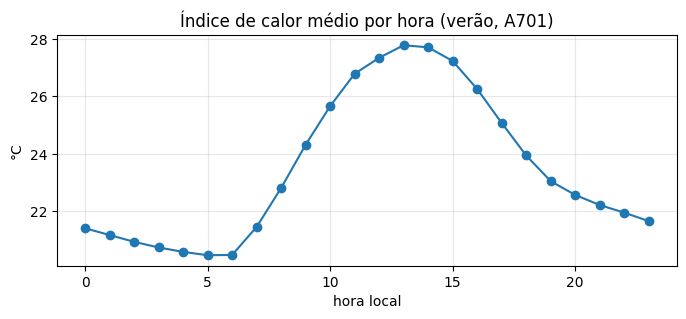

In [4]:
verao = df[df.local.dt.month.isin([12, 1, 2, 3])]
verao.groupby(verao.local.dt.hour)['indice'].mean().plot(marker='o', figsize=(8, 3), title='Índice de calor médio por hora (verão, A701)')
plt.xlabel('hora local'); plt.ylabel('°C'); plt.grid(alpha=.3); plt.show()

## 3. Atributos e alvo
Só atributos que **existem em produção** (o boletim horário do INMET): temperatura, umidade, hora local (em seno e cosseno, para o modelo entender que 23h fica perto de 0h), mês, variação da temperatura na última hora e índice de calor atual, calculado pela mesma fórmula da API. O alvo é o índice de calor **2 horas depois**. Só entram linhas com as horas vizinhas presentes (sem buracos). O índice atual responde ao baixo recall encontrado na versão anterior, sem mudar os limites dos níveis do contrato.

In [5]:
uma_h, duas_h = pd.Timedelta(hours=1), pd.Timedelta(hours=2)
anterior = df['temperatura_c'].reindex(df.index - uma_h).to_numpy()
futuro = df['indice'].reindex(df.index + duas_h).to_numpy()
X = pd.DataFrame({
    'temperatura_c': df.temperatura_c,
    'umidade_pct': df.umidade_pct,
    'hora_sen': np.sin(2 * np.pi * df.local.dt.hour / 24),
    'hora_cos': np.cos(2 * np.pi * df.local.dt.hour / 24),
    'mes_sen': np.sin(2 * np.pi * df.local.dt.month / 12),
    'mes_cos': np.cos(2 * np.pi * df.local.dt.month / 12),
    'variacao_1h': df.temperatura_c.to_numpy() - anterior,
    'indice_agora': df['indice'],
}, index=df.index)
dados = X.assign(alvo=futuro).dropna()
ano = dados.index.year
treino = dados[(ano <= 2023) & (dados.index + duas_h < pd.Timestamp('2024-01-01', tz='UTC'))]
valid = dados[(ano == 2024) & (dados.index + duas_h < pd.Timestamp('2025-01-01', tz='UTC'))]
teste = dados[ano == 2025]
ATRIBUTOS = list(X.columns)
print('dropna (sem hora anterior ou alvo +2 h):', len(df) - len(dados))
print('exemplos excluídos nas fronteiras:', len(dados) - len(treino) - len(valid) - len(teste))
print('treino', len(treino), '| validação', len(valid), '| teste', len(teste))
assert treino.index.max() + duas_h < valid.index.min()
assert valid.index.max() + duas_h < teste.index.min()

dropna (sem hora anterior ou alvo +2 h): 205
exemplos excluídos nas fronteiras: 4
treino 17192 | validação 8740 | teste 8645


### Distribuições e correlação (treino)
A análise do alvo usa apenas o treino, preservando 2025 para a avaliação final.
As frequências evidenciam o desbalanceamento: MAE e acurácia global podem esconder
erros em `cuidado`. Correlação mede associação linear, sem demonstrar causalidade;
seno e cosseno devem ser interpretados em conjunto.

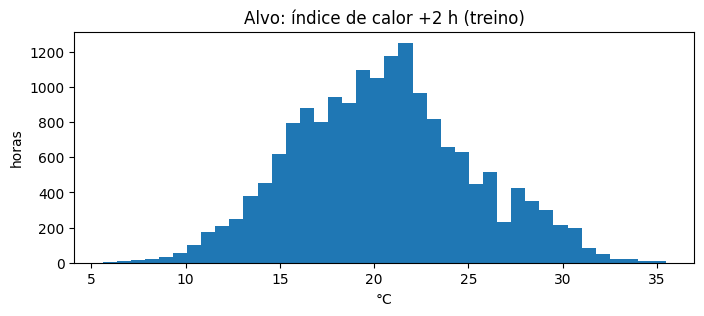

,horas,percentual
alvo,,
normal,15420,89.693
atencao,1668,9.702
cuidado,104,0.605
perigo,0,0.000


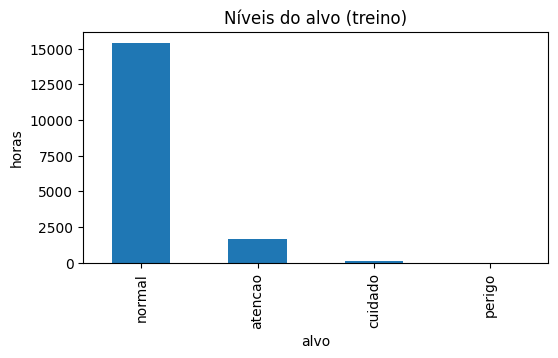

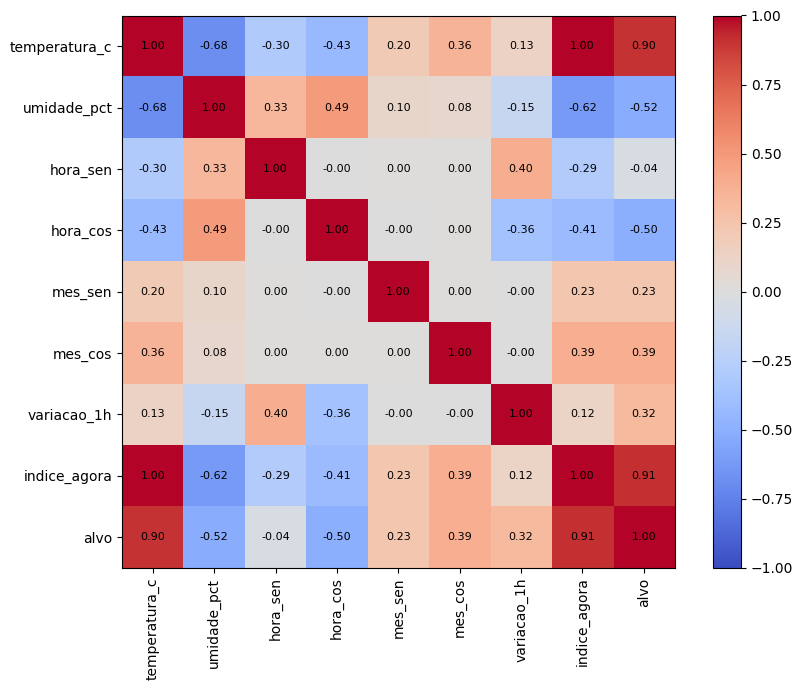

In [6]:
treino.alvo.plot.hist(bins=40, figsize=(8, 3), title='Alvo: índice de calor +2 h (treino)')
plt.xlabel('°C'); plt.ylabel('horas'); plt.show()
contagens = treino.alvo.map(nivel).value_counts().reindex(NIVEIS, fill_value=0)
display(pd.DataFrame({'horas': contagens, 'percentual': (100 * contagens / len(treino)).round(3)}))
contagens.plot.bar(title='Níveis do alvo (treino)', figsize=(6, 3))
plt.ylabel('horas'); plt.show()
correlacao = treino[ATRIBUTOS + ['alvo']].corr()
fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(correlacao, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(correlacao)), correlacao.columns, rotation=90)
ax.set_yticks(range(len(correlacao)), correlacao.columns)
for i in range(len(correlacao)):
    for j in range(len(correlacao)):
        ax.text(j, i, f'{correlacao.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(imagem, ax=ax); plt.tight_layout(); plt.show()

## 4. Modelos
Divisão **por tempo**, sem embaralhar: cada configuração treina só em 2022–2023
 e é medida em 2024. Grade completa: profundidades 4 a 12 e None, folhas de 10 a 50
 (todos os inteiros), 410 configurações. Escolha da árvore pelo menor MAE não arredondado
 de validação; em empate, menor RMSE. Comparamos linear, persistência e uma floresta
 de 100 árvores (profundidade 12, folha 10), sem buscar parâmetros do ensemble.
 Exportamos sempre uma árvore única: a API percorre seus nós em C#, sem Python.
 Nenhum retreino após a escolha. O ano de 2025 fica para a avaliação final.
 Como 2025 já apareceu na auditoria anterior, este é um teste de regressão temporal,
 não uma confirmação independente da revisão; será necessário um período novo.

In [7]:
def avalia(nome, previsto, real):
    reais = [nivel(v) for v in real]
    presentes = [n for n in NIVEIS if n in reais]  # 'perigo' não aparece na A701 em 2022-2025: fica fora da média
    return {'modelo': nome, 'MAE (°C)': round(mean_absolute_error(real, previsto), 3),
            'RMSE (°C)': round(float(np.sqrt(mean_squared_error(real, previsto))), 3),
            'R²': round(r2_score(real, previsto), 3),
            'F1 macro (níveis)': round(f1_score(reais, [nivel(v) for v in previsto], average='macro', labels=presentes, zero_division=0), 3)}

resultados_grade = []
configuracoes = list(ParameterGrid({'max_depth': list(range(4, 13)) + [None],
                                    'min_samples_leaf': list(range(10, 51))}))
arvore, melhor_erro = None, (float('inf'), float('inf'))
for parametros in configuracoes:
    candidata = DecisionTreeRegressor(random_state=42, **parametros).fit(treino[ATRIBUTOS], treino.alvo)
    p = candidata.predict(valid[ATRIBUTOS])
    erros = (mean_absolute_error(valid.alvo, p), float(np.sqrt(mean_squared_error(valid.alvo, p))))
    resultados_grade.append({**parametros, 'MAE (°C)': erros[0], 'RMSE (°C)': erros[1]})
    if erros < melhor_erro:
        arvore, melhor_erro, melhores_parametros = candidata, erros, parametros
assert len(resultados_grade) == 410
grade = pd.DataFrame(resultados_grade)
grade['max_depth'] = grade.max_depth.map(lambda v: 'None' if pd.isna(v) else str(int(v)))
grade = grade.sort_values(['MAE (°C)', 'RMSE (°C)'], kind='stable')
grade.to_csv(PASTA / 'grade-parametros.csv', index=False)
with pd.option_context('display.max_rows', 410):
    display(grade)
print('Melhor árvore:', melhores_parametros, '| MAE e RMSE 2024:', melhor_erro)
linear = LinearRegression().fit(treino[ATRIBUTOS], treino.alvo)
floresta = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10,
                                 random_state=42, n_jobs=1).fit(treino[ATRIBUTOS], treino.alvo)
# Versão anterior: mesma divisão, sete atributos, profundidade 8 e folha 30.
atributos_antes = [a for a in ATRIBUTOS if a != 'indice_agora']
arvore_antes = DecisionTreeRegressor(max_depth=8, min_samples_leaf=30, random_state=42).fit(
    treino[atributos_antes], treino.alvo)
candidatos = {'baseline (agora)': lambda d: d.indice_agora.to_numpy(),
              'regressão linear': lambda d: linear.predict(d[ATRIBUTOS]),
              'floresta (comparação)': lambda d: floresta.predict(d[ATRIBUTOS]),
              'árvore anterior': lambda d: arvore_antes.predict(d[atributos_antes]),
              'árvore ajustada': lambda d: arvore.predict(d[ATRIBUTOS])}
validacao = pd.DataFrame([avalia(n, f(valid), valid.alvo) for n, f in candidatos.items()])
display(validacao)
print('Exportação: árvore única com menor MAE em 2024; ensemble somente para comparação.')

Melhor árvore: {'max_depth': 12, 'min_samples_leaf': 24} | MAE e RMSE 2024: (0.9145401058377538, 1.3427335081644982)
Exportação: árvore única com menor MAE em 2024; ensemble somente para comparação.


,max_depth,min_samples_leaf,MAE (°C),RMSE (°C)
342,12,24,0.914540,1.342734
302,11,25,0.914622,1.342032
343,12,25,0.914723,1.341814
383,None,24,0.914741,1.343079
384,None,25,0.914743,1.342105
385,None,26,0.915082,1.342151
301,11,24,0.915184,1.342792
303,11,26,0.915221,1.342616
344,12,26,0.915289,1.342045
300,11,23,0.916425,1.344671


,modelo,MAE (°C),RMSE (°C),R²,F1 macro (níveis)
0,baseline (agora),1.479,2.084,0.809,0.652
1,regressão linear,1.089,1.494,0.902,0.672
2,floresta (comparação),0.834,1.243,0.932,0.629
3,árvore anterior,0.981,1.390,0.915,0.618
4,árvore ajustada,0.915,1.343,0.921,0.708


### Importância dos atributos
Coeficientes da linear multiplicados pelo desvio padrão de cada atributo no treino:
variação prevista em °C para +1 desvio padrão, mantendo os demais atributos constantes.
A árvore usa redução de impureza, que pode distribuir importância entre atributos
correlacionados; as duas escalas não são diretamente comparáveis.

,coeficiente_padronizado,importancia_arvore
temperatura_c,2.889010,0.006899
umidade_pct,0.666912,0.006923
hora_sen,0.738434,0.049297
hora_cos,-0.548725,0.012509
mes_sen,0.044546,0.001161
mes_cos,0.089099,0.000871
variacao_1h,0.526188,0.042727
indice_agora,1.713410,0.879614


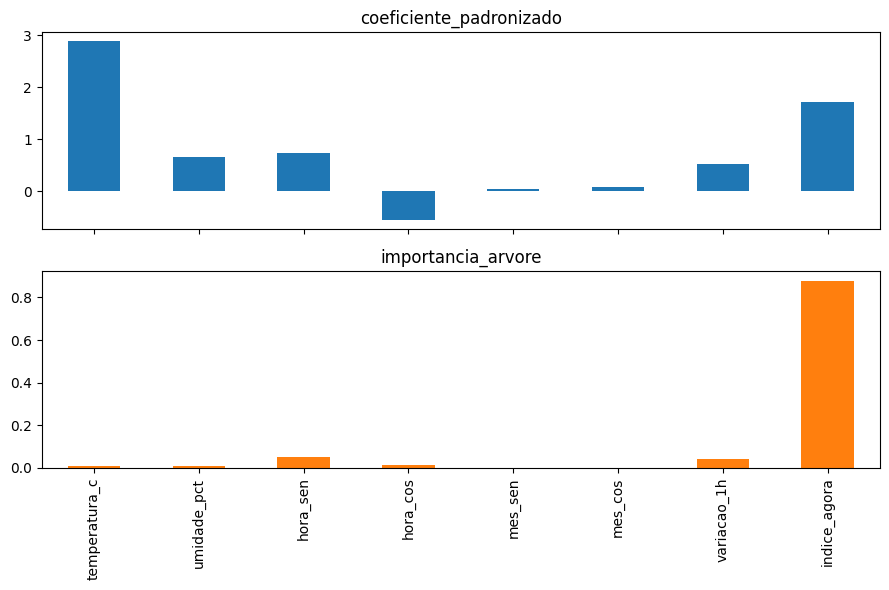

In [8]:
importancias = pd.DataFrame({'coeficiente_padronizado': linear.coef_ * treino[ATRIBUTOS].std(ddof=0),
                              'importancia_arvore': arvore.feature_importances_}, index=ATRIBUTOS)
display(importancias)
importancias.plot.bar(subplots=True, figsize=(9, 6), legend=False)
plt.tight_layout(); plt.show()

In [9]:
escolhido = 'árvore ajustada'
print('modelo escolhido na validação:', escolhido)
previsoes_teste = {n: f(teste) for n, f in candidatos.items()}
resultado_teste = pd.DataFrame([avalia(n, p, teste.alvo) for n, p in previsoes_teste.items()])
resultado_teste

modelo escolhido na validação: árvore ajustada
Out[1]: 
                  modelo  MAE (°C)  RMSE (°C)     R²  F1 macro (níveis)
0       baseline (agora)     1.442      2.021  0.834              0.667
1       regressão linear     1.050      1.448  0.915              0.757
2  floresta (comparação)     0.822      1.220  0.939              0.728
3        árvore anterior     0.958      1.364  0.924              0.660
4        árvore ajustada     0.909      1.324  0.929              0.730


### Onde o modelo acerta e onde erra (teste, 2025)

O `classification_report` inclui os quatro níveis: sua média macro inclui `perigo` com suporte zero. A tabela de regressão usa F1 macro apenas dos níveis presentes, por isso as duas médias diferem.

baseline (agora)
              precision    recall  f1-score   support

      normal      0.963     0.963     0.963      7697
     atencao      0.661     0.658     0.659       900
     cuidado      0.383     0.375     0.379        48
      perigo      0.000     0.000     0.000         0

   micro avg      0.928     0.928     0.928      8645
   macro avg      0.502     0.499     0.500      8645
weighted avg      0.928     0.928     0.928      8645

árvore ajustada
              precision    recall  f1-score   support

      normal      0.970     0.982     0.976      7697
     atencao      0.798     0.726     0.760       900
     cuidado      0.528     0.396     0.452        48
      perigo      0.000     0.000     0.000         0

   micro avg      0.952     0.952     0.952      8645
   macro avg      0.574     0.526     0.547      8645
weighted avg      0.950     0.952     0.951      8645

Cuidado no teste: 48.0 horas; recall do modelo: 0.396 | baseline: 0.375
Out[1]: 
previsto  atenca

,precision,recall,f1-score,support
baseline (agora),0.382979,0.375000,0.378947,48.0
árvore ajustada,0.527778,0.395833,0.452381,48.0


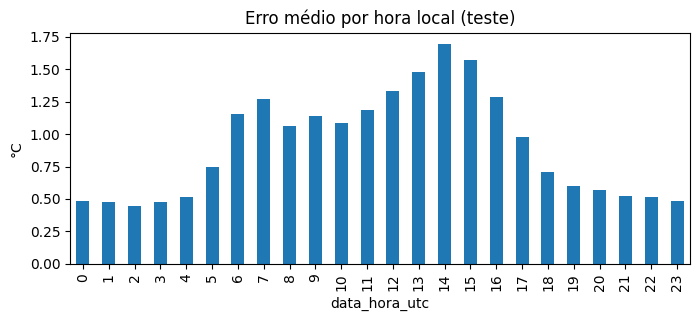

In [10]:
prev = previsoes_teste[escolhido]
relatorios = {}
for nome in ['baseline (agora)', escolhido]:
    reais, previstos = teste.alvo.map(nivel), pd.Series(previsoes_teste[nome]).map(nivel)
    print(nome)
    print(classification_report(reais, previstos, labels=NIVEIS, zero_division=0, digits=3))
    relatorios[nome] = classification_report(reais, previstos, labels=NIVEIS, zero_division=0, output_dict=True)
display(pd.DataFrame({nome: rel['cuidado'] for nome, rel in relatorios.items()}).T)
print('Cuidado no teste:', relatorios[escolhido]['cuidado']['support'],
      'horas; recall do modelo:', round(relatorios[escolhido]['cuidado']['recall'], 3),
      '| baseline:', round(relatorios['baseline (agora)']['cuidado']['recall'], 3))
erro = pd.Series(np.abs(prev - teste.alvo.to_numpy()), index=teste.index)
erro.groupby(teste.index.tz_convert('America/Sao_Paulo').hour).mean().plot(kind='bar', figsize=(8, 3), title='Erro médio por hora local (teste)')
plt.ylabel('°C'); plt.show()
pd.crosstab(pd.Series([nivel(v) for v in teste.alvo], name='real'), pd.Series([nivel(v) for v in prev], name='previsto'))

### Alerta antes e depois
Alerta significa índice previsto **≥ 32 °C** (cuidado ou perigo), sem alterar a tabela
 do contrato. Comparamos a árvore anterior (sete atributos), a revisão (índice atual
 incluído e grade ampliada) e a persistência. Precisão, recall e contagens são medidos
 em 2024 e depois em 2025; não calibramos um novo limiar no teste.
 São alertas da rua: o delta da sala ainda precisa de validação com medições reais.

In [11]:
from sklearn.metrics import precision_score, recall_score
alertas = []
for periodo, conjunto in [('validação 2024', valid), ('teste 2025', teste)]:
    real = conjunto.alvo.to_numpy() >= 32
    for nome in ['baseline (agora)', 'árvore anterior', escolhido]:
        previsto = candidatos[nome](conjunto) >= 32
        tp = int(np.sum(real & previsto))
        fp = int(np.sum(~real & previsto))
        fn = int(np.sum(real & ~previsto))
        assert tp + fn == int(real.sum())
        alertas.append({'período': periodo, 'modelo': nome, 'TP': tp, 'FP': fp, 'FN': fn,
                        'precisão': precision_score(real, previsto, zero_division=0),
                        'recall': recall_score(real, previsto, zero_division=0)})
alertas = pd.DataFrame(alertas)
display(alertas)
alertas.to_csv(PASTA / 'alertas.csv', index=False)

,período,modelo,TP,FP,FN,precisão,recall
0,validação 2024,baseline (agora),37,57,57,0.393617,0.393617
1,validação 2024,árvore anterior,8,8,86,0.500000,0.085106
2,validação 2024,árvore ajustada,32,31,62,0.507937,0.340426
3,teste 2025,baseline (agora),18,29,30,0.382979,0.375000
4,teste 2025,árvore anterior,7,5,41,0.583333,0.145833
5,teste 2025,árvore ajustada,19,17,29,0.527778,0.395833


## 5. Exportar `modelo.json`
A API (C#) carrega este arquivo e aplica o modelo: não há servidor Python em produção. O JSON leva os atributos na ordem, os coeficientes (linear) ou os nós da árvore, e as métricas de teste.

In [12]:
def arvore_json(m):
    t = m.tree_
    def no(i):
        if t.children_left[i] == -1:
            return {'valor': round(float(t.value[i][0][0]), 4)}
        return {'atributo': ATRIBUTOS[t.feature[i]], 'limite': round(float(t.threshold[i]), 6),
                'menor_ou_igual': no(t.children_left[i]), 'maior': no(t.children_right[i])}
    return no(0)

metricas = resultado_teste.set_index('modelo').loc[escolhido].to_dict()
base = resultado_teste.set_index('modelo').loc['baseline (agora)'].to_dict()
modelo = {'versao': 1, 'alvo': 'indice_calor_c em 2 h', 'horizonte_horas': 2, 'atributos': ATRIBUTOS,
          'fonte': 'INMET A701, horário, 2022-2025 (treino 2022-2023, validação 2024, teste 2025)',
          'metricas_teste': metricas, 'baseline_teste': base}
modelo |= {'tipo': 'arvore', 'raiz': arvore_json(arvore)}
with open(PASTA / 'modelo.json', 'w', encoding='utf-8') as f:
    json.dump(modelo, f, ensure_ascii=False, indent=1)
print('modelo.json:', modelo['tipo'], metricas)

modelo.json: arvore {'MAE (°C)': 0.909, 'RMSE (°C)': 1.324, 'R²': 0.929, 'F1 macro (níveis)': 0.73}


Conferência: a mesma previsão feita lendo o JSON (como a API vai fazer) bate com o modelo do scikit-learn.

In [13]:
def prever_json(m, linha):
    if m['tipo'] == 'linear':
        return m['intercepto'] + sum(m['coeficientes'][a] * linha[a] for a in m['atributos'])
    n = m['raiz']
    while 'valor' not in n:
        n = n['menor_ou_igual'] if linha[n['atributo']] <= n['limite'] else n['maior']
    return n['valor']

with open(PASTA / 'modelo.json', encoding='utf-8') as f:
    exportado = json.load(f)
amostra = teste.sample(200, random_state=1)
referencia = pd.Series(prev, index=teste.index)
diferenca = max(abs(prever_json(exportado, r) - referencia.loc[i]) for i, r in amostra.iterrows())
assert diferenca < 0.01, diferenca
print('diferença máxima JSON x scikit-learn:', round(diferenca, 5))
paridade = amostra[ATRIBUTOS].copy()
paridade['previsto'] = arvore.predict(amostra[ATRIBUTOS])
paridade.to_json(PASTA / 'paridade-api.json', orient='records', indent=1, double_precision=15)
print('paridade-api.json:', len(paridade), 'previsões do scikit-learn para o teste da API')

diferença máxima JSON x scikit-learn: 5e-05
paridade-api.json: 200 previsões do scikit-learn para o teste da API


## 6. Previsão em uso
O mesmo vetor do teste da API (`PrevisorModeloTestes.cs`): 15/01/2026 às 17:00 UTC
(14h em São Paulo), rua a 30 °C e 50% de umidade, 1,5 °C mais quente que uma hora antes.
A previsão sai do `modelo.json` percorrido como a API faz. Depois soma-se o *delta*
da sala: a diferença média sala − rua das últimas 3 h, medida pelo ESP32. Aqui o delta
é o valor de exemplo da sala 3 no modo demonstração (+4 °C), não uma medição real.
O nível e a ação sugerida seguem a tabela do `CONTRATO.md`.

In [14]:
ACOES = {'normal': 'nenhuma',
         'atencao': 'liberar água, abrir janelas e ligar ventiladores',
         'cuidado': 'pausa, troca de sala ou adiar Educação Física',
         'perigo': 'tirar a turma da sala'}
agora_utc = pd.Timestamp('2026-01-15 17:00', tz='UTC')
local = agora_utc.tz_convert('America/Sao_Paulo')
entrada = {'temperatura_c': 30.0, 'umidade_pct': 50.0,
           'hora_sen': np.sin(2 * np.pi * local.hour / 24), 'hora_cos': np.cos(2 * np.pi * local.hour / 24),
           'mes_sen': np.sin(2 * np.pi * local.month / 12), 'mes_cos': np.cos(2 * np.pi * local.month / 12),
           'variacao_1h': 1.5, 'indice_agora': indice_calor_c(30.0, 50)}
rua_prevista = prever_json(exportado, entrada)
assert abs(rua_prevista - arvore.predict(pd.DataFrame([entrada])[ATRIBUTOS])[0]) < 0.01
vetores = []
for temp, umidade, hora, mes, variacao in [(30, 50, 14, 1, 1.5), (18, 80, 0, 7, -0.4), (27.2, 62, 12, 12, 0)]:
    x = {'temperatura_c': temp, 'umidade_pct': umidade, 'hora_sen': np.sin(2*np.pi*hora/24),
         'hora_cos': np.cos(2*np.pi*hora/24), 'mes_sen': np.sin(2*np.pi*mes/12),
         'mes_cos': np.cos(2*np.pi*mes/12), 'variacao_1h': variacao, 'indice_agora': indice_calor_c(temp, umidade)}
    vetores.append({**x, 'previsto': prever_json(exportado, x)})
print('Vetores para PrevisorModeloTestes:')
display(pd.DataFrame(vetores))
DELTA_SALA_3 = 4.0  # exemplo do modo demonstração, não medição
sala_prevista = rua_prevista + DELTA_SALA_3
display(pd.DataFrame({'valor': [f"{local:%d/%m/%Y %Hh} (São Paulo)", f"{indice_calor_c(30.0, 50)} °C ({nivel(indice_calor_c(30.0, 50))})",
                                f"{rua_prevista:.2f} °C", f"+{DELTA_SALA_3:.0f} °C", f"{sala_prevista:.2f} °C",
                                nivel(sala_prevista), ACOES[nivel(sala_prevista)]]},
                     index=['agora', 'índice da rua agora', 'rua prevista para +2 h', 'delta da sala 3',
                            'sala prevista para +2 h', 'nível previsto', 'ação sugerida']))

Vetores para PrevisorModeloTestes:


,temperatura_c,umidade_pct,hora_sen,hora_cos,mes_sen,mes_cos,variacao_1h,indice_agora,previsto
0,30.0,50,-5.000000e-01,-0.866025,5.000000e-01,0.866025,1.5,31.0,27.1583
1,18.0,80,0.000000e+00,1.000000,-5.000000e-01,-0.866025,-0.4,17.9,17.4843
2,27.2,62,1.224647e-16,-1.000000,-2.449294e-16,1.000000,0.0,28.5,26.6333


,valor
agora,15/01/2026 14h (São Paulo)
índice da rua agora,31.0 °C (atencao)
rua prevista para +2 h,27.16 °C
delta da sala 3,+4 °C
sala prevista para +2 h,31.16 °C
nível previsto,atencao
ação sugerida,"liberar água, abrir janelas e ligar ventiladores"


### Previsto contra real e resíduos (teste, 2025)
A semana em torno da hora mais quente de 2025 mostra o modelo escolhido e o baseline
contra o índice que de fato ocorreu 2 h depois. O histograma mostra a distribuição
do erro (previsto − real) em todo o teste.

resíduo médio: -0.032 °C | 90% dos erros entre -2.11 e 2.08 °C


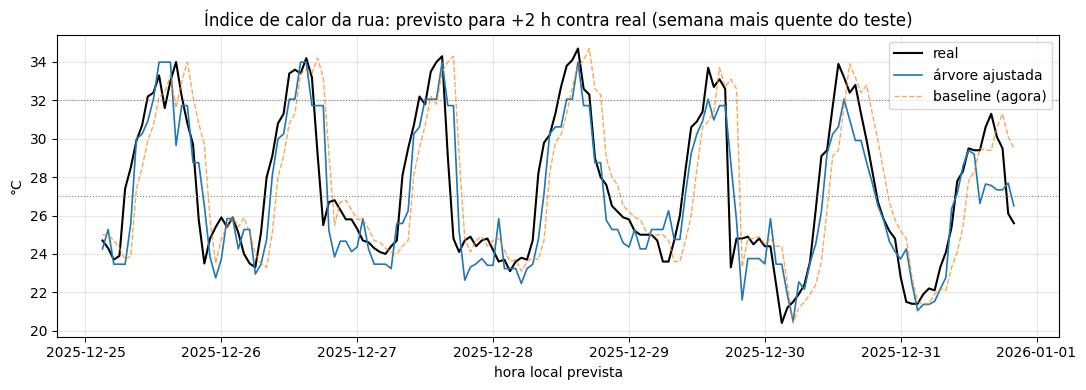

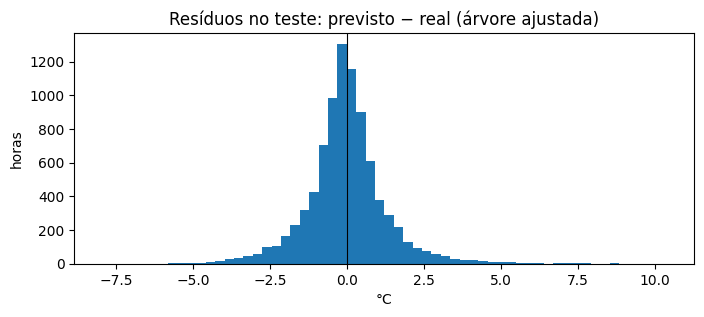

In [15]:
pico = teste.alvo.idxmax()
semana = teste.loc[pico - pd.Timedelta(days=3.5): pico + pd.Timedelta(days=3.5)]
quando = (semana.index + duas_h).tz_convert('America/Sao_Paulo')
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(quando, semana.alvo, label='real', color='black', linewidth=1.5)
ax.plot(quando, pd.Series(prev, index=teste.index).loc[semana.index], label=escolhido, linewidth=1.2)
ax.plot(quando, semana.indice_agora, label='baseline (agora)', linestyle='--', linewidth=1, alpha=.7)
for limite in (27, 32):
    ax.axhline(limite, color='grey', linestyle=':', linewidth=.8)
ax.set_title('Índice de calor da rua: previsto para +2 h contra real (semana mais quente do teste)')
ax.set_ylabel('°C'); ax.set_xlabel('hora local prevista'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
residuos = pd.Series(prev - teste.alvo.to_numpy(), index=teste.index)
residuos.plot.hist(bins=60, figsize=(8, 3), title=f'Resíduos no teste: previsto − real ({escolhido})')
plt.axvline(0, color='black', linewidth=.8); plt.xlabel('°C'); plt.ylabel('horas'); plt.show()
print('resíduo médio:', round(residuos.mean(), 3), '°C | 90% dos erros entre',
      round(residuos.quantile(.05), 2), 'e', round(residuos.quantile(.95), 2), '°C')

## 7. Conclusões e limitações
- O modelo é comparado com o baseline "daqui a 2 h = agora", que é o que uma pessoa faria olhando o termômetro. A tabela de teste mostra quanto ele ganha.
- `Cuidado` é raro: o relatório mostra seu recall e a comparação com o baseline, pois o F1 macro não basta para avaliar a segurança. `Perigo` não aparece nesta base; suporte zero não comprova capacidade de previsão desse nível. Não há garantia de detectar todos os episódios críticos, nem validação da previsão dentro da sala.
- A tabela de regressão e a comparação de precisão/recall mostram separadamente erro em graus e alerta. O índice atual responde ao limite da versão anterior; os limites continuam 27, 32 e 41 °C. Nenhum limiar foi escolhido em 2025. O atributo adicional não garante detectar todos os episódios; falsos negativos e falsos positivos devem acompanhar a demonstração.
- O aviso com 2 h de antecedência apoia a decisão da coordenação de hidratar, ventilar ou realocar a turma, ligado ao **ODS 3.d** (alerta precoce e redução de riscos à saúde). O impacto deve ser medido por aulas em Perigo sem ação, ainda sem evidência medida neste estudo; a previsão não substitui a leitura atual nem os protocolos da escola.
- A previsão é da **rua**. A sala entra pela regra do delta (média das últimas 3 h da diferença sala − rua, medida pelo ESP32), que é simples e auditável. Ela supõe que a diferença das últimas 3 h se mantém nas próximas 2 h; no fim da tarde tende a superestimar.
- Os dados são públicos e reais (INMET). As leituras da sala no Wokwi e no modo demonstração são simuladas, e o README diz isso.
- Próximo passo: com uma semana de leituras reais da sala (termo-higrômetro anotado pelo professor), avaliar a previsão completa da sala contra o que a sala realmente teve 2 h depois.

## 8. Mapa térmico da sala
**Tudo nesta seção é simulado**, não é medição da escola. Sala 7 de 7 × 9 m,
quatro sensores e seis lugares (dois vulneráveis, sem cadastro de pessoas).
São 14 dias por estação, de hora em hora, seed 42: janela quente à tarde no verão
e parede externa fria de madrugada no inverno, com variação diária e ruído de 0,2 °C.
O índice usa a mesma fórmula acima; interpolamos temperatura e índice separadamente.
Os lugares são estimativas derivadas dos quatro sensores, não novas observações.

IDW usa potência 2 e grade de 0,5 m, preserva o valor sobre o sensor e ignora leituras
ausentes. Em uso, selecionar só a última leitura por sensor com até 15 minutos.
A média da sala é a média dos quatro sensores. As funções abaixo também estão em `mapa.py`;
ficam incluídas para executar este notebook sozinho.

In [16]:
"""Mapa da Sala 7 e estudo com dados exclusivamente simulados."""
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (f1_score, mean_absolute_error, mean_squared_error,
                             r2_score, silhouette_score)

SEED = 42
LARGURA, PROFUNDIDADE = 7, 9
SENSORES = [dict(nome=n, x=x, y=y) for n, x, y in
            [('janela', 0, 4), ('fundo', 7, 9), ('porta', 7, 0), ('centro', 3.5, 4.5)]]
LUGARES = [dict(nome=f'lugar {i + 1}', x=x, y=y, vulneravel=i < 2)
           for i, (x, y) in enumerate([(1, 4), (6, 8), (2, 2), (5, 2), (2, 6), (5, 6)])]
CORES = {'frio': 'blue', 'normal': 'green', 'atencao': 'orange',
         'cuidado': 'red', 'perigo': 'darkred'}


def leituras_recentes(leituras, agora):
    recentes = {}
    for leitura in leituras:
        instante = pd.Timestamp(leitura['instante'])
        if pd.Timedelta(0) <= agora - instante <= pd.Timedelta(minutes=15):
            nome = leitura['nome']
            if nome not in recentes or instante > pd.Timestamp(recentes[nome]['instante']):
                recentes[nome] = leitura
    return list(recentes.values())


def nivel(valor):
    if not math.isfinite(valor):
        raise ValueError('Índice deve ser finito')
    return ('frio' if valor < 18 else 'normal' if valor < 27 else
            'atencao' if valor < 32 else 'cuidado' if valor < 41 else 'perigo')


def idw(sensores, x, y, campo='temperatura_c'):
    """Potência 2; None/NaN não participa. Sem leituras, retorna None.

    O chamador fornece uma única leitura recente por sensor (até 15 minutos).
    """
    if not math.isfinite(x) or not math.isfinite(y):
        raise ValueError('Coordenadas devem ser finitas')
    soma, pesos = 0.0, 0.0
    for sensor in sensores:
        valor = sensor.get(campo)
        if valor is None or not math.isfinite(valor):
            continue
        sx, sy = sensor['x'], sensor['y']
        if not math.isfinite(sx) or not math.isfinite(sy):
            raise ValueError('Coordenadas devem ser finitas')
        distancia2 = (x - sx) ** 2 + (y - sy) ** 2
        if distancia2 == 0:
            return float(valor)
        peso = 1 / distancia2
        soma += peso * valor
        pesos += peso
    return soma / pesos if pesos else None


def grade(sensores):
    return pd.DataFrame([{'x': x, 'y': y,
                          'temperatura_c': idw(sensores, x, y),
                          'indice': idw(sensores, x, y, 'indice')}
                         for y in np.arange(0, PROFUNDIDADE + .5, .5)
                         for x in np.arange(0, LARGURA + .5, .5)])


def precaucoes(pontos):
    """Recebe sensores e lugares com índice; nenhum dado pessoal é necessário."""
    pontos = [p for p in pontos if p.get('indice') is not None
              and math.isfinite(p['indice'])]
    lugares = [p for p in pontos if p.get('tipo') != 'sensor']
    avisos = []

    def distancia_normal(p):
        return max(18 - p['indice'], 0, p['indice'] - 27)

    for ponto in lugares:
        if ponto.get('vulneravel') and nivel(ponto['indice']) in ('frio', 'cuidado', 'perigo'):
            candidatos = [p for p in lugares if p['nome'] != ponto['nome']]
            if candidatos:
                destino = min(candidatos, key=lambda p: (distancia_normal(p),
                              nivel(p['indice']) != 'normal', p['nome']))
                if distancia_normal(destino) < distancia_normal(ponto):
                    avisos.append(f"trocar {ponto['nome']} para {destino['nome']} "
                                  f"({ponto['indice']:.1f} → {destino['indice']:.1f} °C)")
                    continue
            avisos.append(f"{ponto['nome']}: sem lugar mais seguro; procurar outro ambiente")
    if pontos:
        frio, quente = min(pontos, key=lambda p: p['indice']), max(pontos, key=lambda p: p['indice'])
        diferenca = quente['indice'] - frio['indice']
        if diferenca >= 4:
            avisos.append(f"ambiente desigual: verificar janela, sol e corrente de ar perto de "
                          f"{quente['nome']} e {frio['nome']} (diferença {diferenca:.1f} °C)")
    return avisos


def simular(indice_calor):
    """14 dias horários por estação, hora local de São Paulo, seed fixo."""
    rng = np.random.default_rng(SEED)
    linhas = []
    for estacao, inicio, base in [('verao', '2026-01-01', 28), ('inverno', '2026-07-01', 19)]:
        dias = rng.normal(0, .8, 14)
        for instante in pd.date_range(inicio, periods=14 * 24, freq='h', tz='America/Sao_Paulo'):
            h = instante.hour
            temperatura = base + 3.5 * np.cos(2 * np.pi * (h - 15) / 24) + dias[instante.day - 1]
            umidade = np.clip(65 - 1.3 * (temperatura - base) + rng.normal(0, 2), 35, 90)
            sensores = []
            for sensor in SENSORES:
                desvio = {'janela': .8, 'fundo': -.8, 'porta': -.4, 'centro': .1}[sensor['nome']]
                if estacao == 'verao' and sensor['nome'] == 'janela':
                    desvio += 5 * np.exp(-((h - 15) / 3) ** 2)
                if estacao == 'inverno' and sensor['nome'] == 'fundo':
                    desvio -= 3.5 * np.exp(-((h - 4) / 3) ** 2)
                temp = temperatura + desvio + rng.normal(0, .2)
                sensores.append(dict(sensor, temperatura_c=temp, umidade_pct=float(umidade),
                                     indice=indice_calor(temp, umidade)))
            pontos = sensores + [dict(p, temperatura_c=idw(sensores, p['x'], p['y']),
                                      umidade_pct=float(umidade),
                                      indice=idw(sensores, p['x'], p['y'], 'indice')) for p in LUGARES]
            media = np.mean([p['indice'] for p in sensores])
            for ponto in pontos:
                linhas.append(dict(ponto, estacao=estacao, instante=instante,
                                   hora=h, dia=instante.day, origem='simulada', ambiente='Sala 7',
                                   tipo='sensor' if ponto['nome'] in [s['nome'] for s in SENSORES] else 'lugar',
                                   desvio_ponto=ponto['indice'] - media, nivel=nivel(ponto['indice'])))
    return pd.DataFrame(linhas)


def agrupar(dados):
    """Perfil médio de 24 h por ponto; estações analisadas separadamente."""
    resultados, avaliacoes = [], []
    for estacao, dados_estacao in dados.groupby('estacao', sort=True):
        perfil = dados_estacao.pivot_table(index='nome', columns='hora', values='indice')
        desvios = dados_estacao.groupby('nome').desvio_ponto
        if perfil.shape[1] != 24 or perfil.isna().any().any():
            raise ValueError('Cada ponto precisa de um perfil completo de 24 horas')
        candidatos = []
        for k in range(2, 5):
            grupos = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(perfil)
            silhueta = silhouette_score(perfil, grupos)
            candidatos.append((silhueta, k, grupos))
            avaliacoes.append(dict(estacao=estacao, k=k, silhueta=silhueta))
        _, k, grupos = max(candidatos, key=lambda c: (c[0], -c[1]))
        for nome, grupo in zip(perfil.index, grupos):
            d = desvios.get_group(nome)
            cronico = 'quente' if (d > 0).all() else 'frio' if (d < 0).all() else 'variavel'
            resultados.append(dict(estacao=estacao, nome=nome, grupo=int(grupo), k=k,
                                   cronico=cronico, desvio_medio=float(d.mean())))
    return pd.DataFrame(resultados), pd.DataFrame(avaliacoes)


def prever_json(modelo, linha):
    if modelo['tipo'] == 'correcao_linear':
        return (prever_json(modelo['modelo_base'], linha) + modelo['intercepto'] +
                sum(modelo['coeficientes'][a] * linha[a] for a in modelo['atributos']))
    no = modelo['raiz']
    while 'valor' not in no:
        no = no['menor_ou_igual'] if linha[no['atributo']] <= no['limite'] else no['maior']
    return no['valor']


def preparar_previsao(dados):
    partes = []
    for (_, _), ponto in dados.groupby(['estacao', 'nome']):
        ponto = ponto.sort_values('instante').copy()
        ponto['alvo'] = ponto.indice.shift(-2)
        ponto['dia_alvo'] = ponto.dia.shift(-2)
        ponto['variacao_1h'] = ponto.temperatura_c.diff()
        for nome, valor, periodo in [('hora', ponto.hora, 24), ('mes', ponto.instante.dt.month, 12)]:
            ponto[nome + '_sen'] = np.sin(2 * np.pi * valor / periodo)
            ponto[nome + '_cos'] = np.cos(2 * np.pi * valor / periodo)
        ponto['indice_agora'] = ponto.indice
        partes.append(ponto)
    return pd.concat(partes).dropna(subset=['alvo', 'variacao_1h'])


def treinar_pontos(dados, modelo_base):
    dados = preparar_previsao(dados)
    treino = dados[(dados.dia <= 10) & (dados.dia_alvo <= 10)]
    teste = dados[dados.dia > 10]
    atributos = modelo_base['atributos'] + ['desvio_ponto']
    base_treino = np.array([prever_json(modelo_base, r) for r in treino.to_dict('records')])
    correcao = LinearRegression().fit(treino[atributos], treino.alvo - base_treino)
    modelo = dict(tipo='correcao_linear', versao=1, modelo_base=modelo_base,
                  alvo='indice_calor_c do ponto em 2 h', horizonte_horas=2,
                  fonte='Sala 7, dados simulados, seed 42, 14 dias por estação',
                  atributos=atributos, intercepto=float(correcao.intercept_),
                  coeficientes=dict(zip(atributos, map(float, correcao.coef_))))
    base_teste = np.array([prever_json(modelo_base, r) for r in teste.to_dict('records')])
    previstos = base_teste + correcao.predict(teste[atributos])
    metricas = []
    for nome, valores in [('persistencia', teste.indice), ('modelo_atual', base_teste),
                          ('modelo_atual_mais_desvio', base_teste + teste.desvio_ponto),
                          ('modelo_pontos', previstos)]:
        metricas.append(dict(modelo=nome, MAE=mean_absolute_error(teste.alvo, valores),
                             RMSE=float(np.sqrt(mean_squared_error(teste.alvo, valores))),
                             R2=r2_score(teste.alvo, valores),
                             F1_macro=f1_score(teste.alvo.map(nivel), [nivel(v) for v in valores], average='macro')))
    metricas = pd.DataFrame(metricas)
    modelo['metricas_teste'] = metricas.to_dict('records')
    modelo['divisao'] = dict(treino=len(treino), teste=len(teste),
                             regra='dias 1–10 treino, 11–14 teste por estação; alvo sem cruzar a fronteira')
    paridade = teste[atributos].copy()
    paridade['previsto'] = previstos
    return modelo, metricas, paridade


def exportar_modelo(modelo, caminho):
    caminho = Path(caminho)
    conteudo = json.dumps(modelo, ensure_ascii=False, indent=1, allow_nan=False)
    temporario = caminho.with_suffix(caminho.suffix + '.novo')
    temporario.write_text(conteudo, encoding='utf-8')
    temporario.replace(caminho)


In [17]:
simulados = simular(indice_calor_c)
(PASTA / 'dados').mkdir(parents=True, exist_ok=True)
simulados.to_csv(PASTA / 'dados/sala7-simulada.csv', index=False)
print(len(simulados), 'registros simulados; sensores e lugares estimados')
display(simulados.groupby(['estacao', 'tipo']).size().rename('registros'))
grupos, silhuetas = agrupar(simulados)
display(silhuetas)
display(grupos)
grupos.to_csv(PASTA / 'grupos-pontos.csv', index=False)
silhuetas.to_csv(PASTA / 'silhuetas-pontos.csv', index=False)

6720 registros simulados; sensores e lugares estimados


C:\Users\samue\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\samue\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^

estacao  tipo  
inverno  lugar     2016
         sensor    1344
verao    lugar     2016
         sensor    1344
Name: registros, dtype: int64

,estacao,k,silhueta
0,inverno,2,0.741533
1,inverno,3,0.635126
2,inverno,4,0.639685
3,verao,2,0.691635
4,verao,3,0.661615
5,verao,4,0.676744


,estacao,nome,grupo,k,cronico,desvio_medio
0,inverno,centro,0,2,variavel,0.402976
1,inverno,fundo,1,2,frio,-1.448810
2,inverno,janela,0,2,quente,1.177679
3,inverno,lugar 1,0,2,quente,1.020108
4,inverno,lugar 2,1,2,frio,-1.158550
5,inverno,lugar 3,0,2,quente,0.586609
6,inverno,lugar 4,0,2,variavel,0.149332
7,inverno,lugar 5,0,2,quente,0.488482
8,inverno,lugar 6,0,2,variavel,0.042988
9,inverno,porta,0,2,variavel,-0.131845


### Agrupamento e pontos crônicos
K-means compara perfis médios de 24 horas em °C, sem padronizar para preservar
diferenças de temperatura. Escolhemos k de 2 a 4 pela maior silhueta, por estação.
Crônico quente/frio significa desvio positivo/negativo em **todas as leituras individuais**
da estação; qualquer inversão de sinal ou igualdade torna o ponto variável. Os lugares interpolados
compartilham informação dos sensores e não são amostras independentes.

verao ['trocar lugar 1 para lugar 2 (52.1 → 37.4 °C)', 'lugar 2: sem lugar mais seguro; procurar outro ambiente', 'ambiente desigual: verificar janela, sol e corrente de ar perto de janela e porta (diferença 18.9 °C)']
inverno ['lugar 1: sem lugar mais seguro; procurar outro ambiente', 'trocar lugar 2 para lugar 1 (12.9 → 17.6 °C)', 'ambiente desigual: verificar janela, sol e corrente de ar perto de janela e fundo (diferença 5.7 °C)']


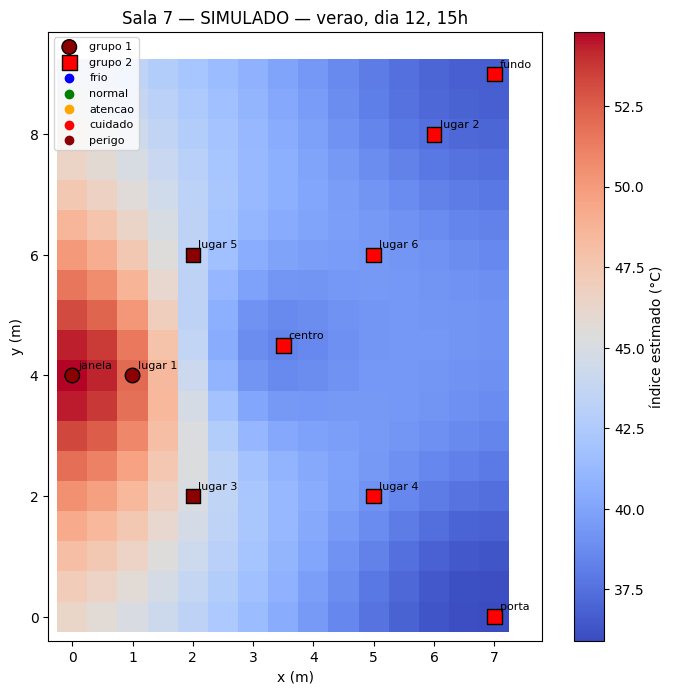

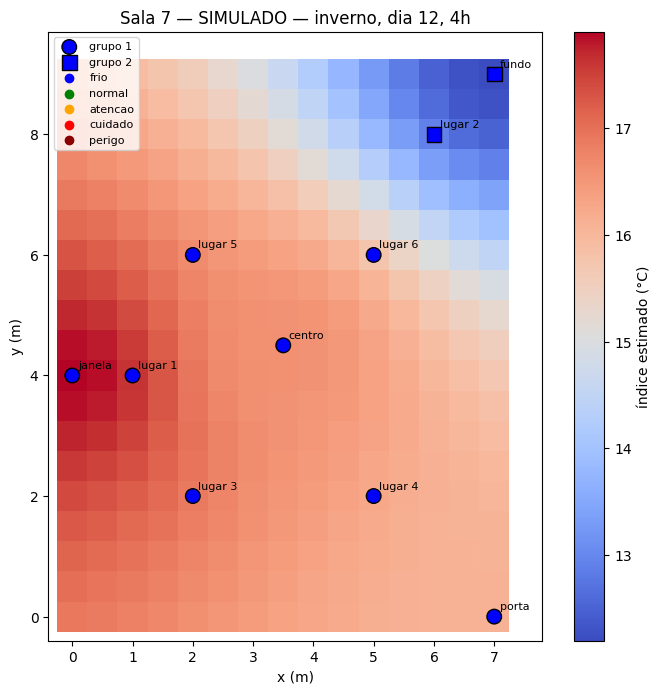

In [18]:
for estacao, hora in [('verao', 15), ('inverno', 4)]:
    retrato = simulados[(simulados.estacao == estacao) & (simulados.dia == 12) & (simulados.hora == hora)]
    sensores = retrato[retrato.tipo == 'sensor'].to_dict('records')
    superficie = grade(sensores)
    pontos = retrato.merge(grupos, on=['estacao', 'nome'])
    fig, ax = plt.subplots(figsize=(7, 7))
    imagem = ax.pcolormesh(superficie.x.unique(), superficie.y.unique(),
                           superficie.indice.to_numpy().reshape(19, 15), cmap='coolwarm', shading='auto')
    fig.colorbar(imagem, ax=ax, label='índice estimado (°C)')
    for grupo, parte in pontos.groupby('grupo'):
        ax.scatter(parte.x, parte.y, c=parte.nivel.map(CORES), marker=['o', 's', '^', 'D'][grupo],
                   s=110, edgecolors='black', label=f'grupo {grupo + 1}')
    for p in pontos.to_dict('records'):
        ax.annotate(p['nome'], (p['x'], p['y']), xytext=(4, 5), textcoords='offset points', fontsize=8)
    for faixa, cor in CORES.items():
        ax.scatter([], [], color=cor, label=faixa)
    ax.set(xlim=(-.4, 7.8), ylim=(-.4, 9.7), xlabel='x (m)', ylabel='y (m)',
           title=f'Sala 7 — SIMULADO — {estacao}, dia 12, {hora}h')
    ax.set_aspect('equal'); ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.show()
    print(estacao, precaucoes(retrato.to_dict('records')))

### Previsão por ponto (+2 h)
Reutilizamos a árvore de `modelo.json`, congelada. Uma regressão linear aprende
o resíduo da árvore com os oito atributos originais e `desvio_ponto` (índice do
ponto menos média dos sensores no mesmo instante). A correção fica em
`modelo_pontos.json`, que contém a árvore base e seus coeficientes, sem substituir
o arquivo original. Este formato separado ainda precisa de um consumidor próprio.
Treino nos dias 1–10 de cada estação; teste nos dias 11–14, sem alvo atravessando
a fronteira. Parâmetros fixos, sem escolher modelo no teste.
Comparamos MAE, RMSE, R² e F1 macro com persistência e com a árvore original,
também somando apenas o desvio atual. O teste é simulado e não valida uso real.

In [19]:
modelo_pontos, metricas_pontos, paridade_pontos = treinar_pontos(simulados, exportado)
exportar_modelo(modelo_pontos, PASTA / 'modelo_pontos.json')
metricas_pontos.to_csv(PASTA / 'metricas-pontos.csv', index=False)
print(modelo_pontos['divisao'])
display(metricas_pontos)
recarregado = json.loads((PASTA / 'modelo_pontos.json').read_text(encoding='utf-8'))
erro_json = max(abs(prever_json(recarregado, r) - r['previsto'])
                for r in paridade_pontos.to_dict('records'))
assert erro_json < 1e-9, erro_json
print('Diferença máxima JSON x regressão:', erro_json)
ganho = (metricas_pontos.set_index('modelo').loc['persistencia', 'MAE'] -
         metricas_pontos.set_index('modelo').loc['modelo_pontos', 'MAE'])
print('Redução de MAE contra persistência (negativo = pior):', ganho)

{'treino': 4740, 'teste': 1880, 'regra': 'dias 1–10 treino, 11–14 teste por estação; alvo sem cruzar a fronteira'}
Diferença máxima JSON x regressão: 7.105427357601002e-15
Redução de MAE contra persistência (negativo = pior): 0.6938200642538093


,modelo,MAE,RMSE,R2,F1_macro
0,persistencia,2.034861,2.639037,0.894602,0.653548
1,modelo_atual,2.574577,4.199007,0.733169,0.503186
2,modelo_atual_mais_desvio,2.600614,4.075789,0.748600,0.583804
3,modelo_pontos,1.341040,1.869924,0.947084,0.797982


### Precauções e limites
Lugar vulnerável abaixo de 18 °C ou a partir de 32 °C recebe sugestão de troca
para o lugar com índice mais próximo de [18, 27) °C, somente se houver melhora.
Sem alternativa melhor, procurar outro ambiente. Diferença de pelo menos 4 °C
entre pontos (sensores e lugares) gera aviso de ambiente desigual, indicando extremos calculados.
Não estimamos ocupação nem identificamos moradores/alunos. A interpolação não
modela paredes, obstáculos, radiação solar ou circulação de ar. Quatro sensores
não validam todos os lugares: precisamos de mais sensores reais, calibrados e
posicionados em diferentes alturas, e dados reais em outras épocas para avaliar
os grupos, a previsão e as precauções. Nenhum resultado simulado comprova segurança.